# Sumativa 2 — Validación, simulación y remuestreo
## Características de navegación y compra

**Grupo 9 · Estadística Computacional para la Toma de Decisiones**

**Pregunta:** ¿Se mantienen las diferencias de navegación entre sesiones con compra y sin compra al evaluar su incertidumbre y sensibilidad mediante remuestreo y simulación?

Se validan los resultados de `../Sumativa_1/02_Sumativa1.ipynb`, usando la misma copia MCAR, las mismas unidades y los mismos grupos. Una fila representa una sesión; `Revenue` indica compra, no un monto monetario. El diseño observacional permite interpretar asociaciones, sin atribuir causalidad.

La secuencia comprende trazabilidad de S1, bootstrap de seis medias, medianas complementarias, permutación de dos contrastes, estabilidad de tres correlaciones, simulación Monte Carlo, sensibilidad, revisión de faltantes y resultados validados para S3. El informe sintetiza las salidas de este cuaderno.

## 0 Reproducibilidad y entradas

Ejecutar de principio a fin desde `Sumativa_2`, con el kernel **Python (Estadistica Computacional)** del entorno del repositorio. Las entradas locales se preparan previamente con `01_preparar_datos.ipynb` de S1. No se descargan datos ni se instalan dependencias durante el análisis.

Utilizamos NumPy, pandas, SciPy, Matplotlib y Seaborn; `pathlib` pertenece a Python. Fijamos 10.000 repeticiones y semillas explícitas por procedimiento. Una semilla reproduce la secuencia; no garantiza que el modelo sea correcto ni que haya convergido. Los archivos derivados se guardan dentro de `Sumativa_2/resultados` y las figuras en `Sumativa_2/figuras`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
B = 10_000
ALFA = 0.05
GRUPOS = ['Sin compra', 'Con compra']
VARIABLES = ['Tiempo_minutos', 'ProductRelated', 'Administrative']
NOMBRES = dict(zip(VARIABLES, ['Tiempo en productos', 'Páginas de productos', 'Páginas administrativas']))
COLORES = {'Sin compra': '#35618D', 'Con compra': '#C06A31'}
raiz = Path('..')
resultados_dir = Path('resultados')
figuras_dir = Path('figuras')
resultados_dir.mkdir(exist_ok=True)
figuras_dir.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})

def guardar_tabla(nombre, tabla):
    tabla.to_json(resultados_dir / f'{nombre}.json', orient='records',
                  force_ascii=False, indent=2, double_precision=15)

def guardar_figura(nombre):
    plt.savefig(figuras_dir / f'{nombre}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()

versiones = pd.DataFrame({'Biblioteca': ['NumPy', 'pandas', 'SciPy', 'Matplotlib', 'Seaborn'],
                         'Versión': [np.__version__, pd.__version__, scipy.__version__,
                                     matplotlib.__version__, sns.__version__]})
display(versiones)
guardar_tabla('versiones', versiones)

,Biblioteca,Versión
0,NumPy,2.5.3
1,pandas,2.3.3
2,SciPy,1.18.1
3,Matplotlib,3.11.2
4,Seaborn,0.13.2


### 0.1 Integridad y tratamiento de faltantes

Leemos los tres CSV con `float_precision="round_trip"`. Comprobamos dimensiones, posiciones de las 1.233 ausencias y valores del respaldo. El sorteo original se reconstruye únicamente para comprobarlo; no se vuelven a generar archivos ni a ocultar datos.

La referencia principal utiliza casos disponibles por variable, sin imputar ni eliminar extremos o filas coincidentes. El respaldo se reserva para integridad y una evaluación controlada posterior. Para las tres correlaciones se mantiene exactamente la base de S1: 11.097 casos completos en las tres variables, también para la relación entre ambos conteos.

In [2]:
rutas = {nombre: raiz / 'Sumativa_1' / relativo for nombre, relativo in {
    'original': 'datos_originales/online_shoppers_intention.csv',
    'trabajo': 'datos_trabajo/online_shoppers_mcar.csv',
    'respaldo': 'datos_trabajo/valores_ocultados.csv'}.items()}
for ruta in rutas.values():
    if not ruta.is_file():
        raise FileNotFoundError(f'Falta {ruta}. Revisar la preparación de S1.')
original = pd.read_csv(rutas['original'], float_precision='round_trip')
df = pd.read_csv(rutas['trabajo'], float_precision='round_trip')
respaldo = pd.read_csv(rutas['respaldo'], float_precision='round_trip')
assert original.shape == df.shape == (12330, 18)
assert original.isna().sum().sum() == 0
ocultas = np.sort(np.random.default_rng(42).choice(len(df), 1233, replace=False))
assert np.array_equal(np.flatnonzero(df.ProductRelated_Duration.isna()), ocultas)
assert np.array_equal(respaldo.fila_original, ocultas)
assert np.array_equal(respaldo.valor_original, original.loc[ocultas, 'ProductRelated_Duration'])
control = df.copy()
control.loc[ocultas, 'ProductRelated_Duration'] = respaldo.valor_original.to_numpy()
assert control.equals(original)
del control
df['Tiempo_minutos'] = df.ProductRelated_Duration / 60
df['Grupo'] = df.Revenue.map({False: 'Sin compra', True: 'Con compra'})
completos = df.dropna(subset=VARIABLES).copy()
assert len(completos) == 11097
calidad = pd.DataFrame({'Grupo': GRUPOS,
    'Sesiones': [int((df.Grupo == g).sum()) for g in GRUPOS],
    'Tiempos observados': [int(df.loc[df.Grupo == g, 'Tiempo_minutos'].count()) for g in GRUPOS]})
calidad['Tiempos faltantes'] = calidad.Sesiones - calidad['Tiempos observados']
display(calidad)
guardar_tabla('calidad', calidad)
print('Integridad verificada. Original y archivos de S1 se conservan sin cambios.')

,Grupo,Sesiones,Tiempos observados,Tiempos faltantes
0,Sin compra,10422,9387,1035
1,Con compra,1908,1710,198


Integridad verificada. Original y archivos de S1 se conservan sin cambios.


## 1 Referencia explícita de la Sumativa 1

Recalculamos las seis medias y sus intervalos t del 95%, sin redondeos intermedios. Se conserva el parámetro de cada grupo; un promedio global no sustituye a los dos promedios de S1. El intervalo clásico es $\bar{x}\pm t_{0.975,n-1}s/\sqrt{n}$. También recuperamos las medianas, la desviación estándar muestral y la proporción de ceros para interpretar asimetría y construir escenarios.

Las comparaciones son bilaterales y la diferencia siempre es **con compra menos sin compra**. La independencia de sesiones es un supuesto de trabajo; la representatividad se limita al sitio y período originales.

Los intervalos t son exactos bajo normalidad e independencia; en estas variables asimétricas se emplean como aproximación para la media, apoyada en el tamaño muestral de cada grupo. El bootstrap aporta una comparación de la incertidumbre basada en la distribución empírica, sin garantizar cobertura exacta ni corregir representatividad.

In [3]:
filas = []
for variable in VARIABLES:
    for grupo in GRUPOS:
        x = df.loc[df.Grupo == grupo, variable].dropna().to_numpy(dtype=float)
        n, media, s = len(x), x.mean(), x.std(ddof=1)
        lo, hi = stats.t.interval(0.95, n-1, loc=media, scale=s/np.sqrt(n))
        filas.append({'Variable': variable, 'Nombre': NOMBRES[variable], 'Grupo': grupo,
                      'n': n, 'Media': media, 'Mediana': np.median(x), 'DE': s,
                      'Clasico_inf': lo, 'Clasico_sup': hi, 'Ceros': np.mean(x == 0)})
base_s1 = pd.DataFrame(filas)
assert np.allclose(base_s1.Media, [17.858,30.991,28.715,48.210,2.118,3.394], atol=0.001)
display(base_s1.round(4))
guardar_tabla('base_s1', base_s1)
p_compra = df.Revenue.mean()
print(f'Proporción de compra de S1: {p_compra:.6f} ({100*p_compra:.2f}%).')

,Variable,Nombre,Grupo,n,Media,Mediana,DE,Clasico_inf,Clasico_sup,Ceros
0,Tiempo_minutos,Tiempo en productos,Sin compra,9387,17.8584,8.4556,30.5222,17.2408,18.4759,0.0709
1,Tiempo_minutos,Tiempo en productos,Con compra,1710,30.9912,18.3011,37.6535,29.2053,32.7772,0.0058
2,ProductRelated,Páginas de productos,Sin compra,10422,28.7146,16.0000,40.7447,27.9323,29.4970,0.0031
3,ProductRelated,Páginas de productos,Con compra,1908,48.2102,29.0000,58.2674,45.5940,50.8263,0.0031
4,Administrative,Páginas administrativas,Sin compra,10422,2.1177,0.0000,3.2025,2.0562,2.1792,0.5041
5,Administrative,Páginas administrativas,Con compra,1908,3.3936,2.0000,3.7305,3.2261,3.5611,0.2694


Proporción de compra de S1: 0.154745 (15.47%).


## 2 Validación de medias mediante bootstrap percentil y BCa

Para validar los intervalos de confianza obtenidos en la Sumativa 1, aplicamos el método bootstrap no paramétrico, siguiendo el procedimiento presentado en los apuntes del curso.

Para cada variable y grupo:
1. Generamos 10.000 muestras aleatorias con reemplazo, manteniendo el tamaño de la muestra original.
2. Calculamos la media de cada muestra bootstrap.
3. Construimos intervalos de confianza al 95% utilizando dos métodos:
   - **Percentil:** utiliza directamente los percentiles 2,5 y 97,5 de las medias bootstrap.
   - **BCa:** ajusta los percentiles para considerar posibles sesgos y asimetrías del estimador.
4. Comparamos ambos intervalos con los intervalos clásicos calculados en la Sumativa 1.

Para calcular BCa utilizamos jackknife, que consiste en recalcular el estadístico excluyendo una observación a la vez.(Maidana, 2026b; ejemplo de Sumativa 2).
El código procesa las remuestras por lotes para reducir el uso de memoria, sin modificar el procedimiento estadístico ni la cantidad de remuestras.
El objetivo es evaluar si las estimaciones originales se mantienen consistentes al aplicar métodos alternativos de construcción de intervalos de confianza. 


In [4]:
# Bootstrap no paramétrico:
# 1. Generar muestras con reemplazo.
# 2. Calcular el estadístico en cada muestra.
# 3. Repetir el procedimiento 10.000 veces.
#
# Se utilizan índices aleatorios y procesamiento por lotes
# para reproducir el procedimiento de clase usando menos memoria.

def bootstrap_estadistico(x, estadistico, semilla, repeticiones=B, lote=100):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(semilla)
    replicas = np.empty(repeticiones)
    for inicio in range(0, repeticiones, lote):
        cantidad = min(lote, repeticiones-inicio)
        indices = rng.integers(0, len(x), size=(cantidad, len(x)))
        replicas[inicio:inicio+cantidad] = estadistico(x[indices], axis=1)
    return replicas

# Intervalo BCa (Bias-Corrected and Accelerated):
# z0 corrige el sesgo observado en las remuestras.
# La aceleración se calcula con jackknife.
# Finalmente se obtienen los percentiles ajustados
# que definen los límites del intervalo de confianza.

def bca_media(x, replicas):
    media = x.mean()
    proporcion = (np.sum(replicas < media) + 0.5*np.sum(replicas == media))/len(replicas)
    if not 0 < proporcion < 1:
        raise ValueError('BCa indefinido: revisar distribución bootstrap.')
    z0 = stats.norm.ppf(proporcion)
    jack = (x.sum()-x)/(len(x)-1)
    d = jack.mean()-jack
    denominador = 6 * np.sum(d*d)**1.5
    if denominador == 0:
        raise ValueError('BCa indefinido: jackknife sin variación.')
    aceleracion = np.sum(d**3)/denominador
    z = stats.norm.ppf([0.025, 0.975])
    ajustados = stats.norm.cdf(z0 + (z0+z)/(1-aceleracion*(z0+z)))
    assert 0 < ajustados[0] < ajustados[1] < 1
    return np.quantile(replicas, ajustados), z0, aceleracion

In [5]:
distribuciones_medias, filas = {}, []
for i, fila in base_s1.iterrows():
    variable, grupo = fila.Variable, fila.Grupo
    x = df.loc[df.Grupo == grupo, variable].dropna().to_numpy(dtype=float)
    replicas = bootstrap_estadistico(x, np.mean, SEMILLA+i)
    percentil = np.quantile(replicas, [0.025,0.975])
    bca, z0, a = bca_media(x, replicas)
    registro = fila.to_dict()
    registro.update({'Percentil_inf':percentil[0], 'Percentil_sup':percentil[1],
                     'BCa_inf':bca[0], 'BCa_sup':bca[1], 'z0':z0, 'Aceleracion':a,
                     'SE_bootstrap':replicas.std(ddof=1), 'Semilla':SEMILLA+i, 'B':B})
    registro['Ancho_relativo_BCa'] = (bca[1]-bca[0])/(fila.Clasico_sup-fila.Clasico_inf)
    filas.append(registro)
    distribuciones_medias[(variable,grupo)] = replicas
bootstrap_medias = pd.DataFrame(filas)
display(bootstrap_medias[['Nombre','Grupo','Media','Clasico_inf','Clasico_sup',
                         'Percentil_inf','Percentil_sup','BCa_inf','BCa_sup','Ancho_relativo_BCa']].round(4))
guardar_tabla('bootstrap_medias', bootstrap_medias)

,Nombre,Grupo,Media,Clasico_inf,Clasico_sup,Percentil_inf,Percentil_sup,BCa_inf,BCa_sup,Ancho_relativo_BCa
0,Tiempo en productos,Sin compra,17.8584,17.2408,18.4759,17.2491,18.4969,17.2807,18.5309,1.0123
1,Tiempo en productos,Con compra,30.9912,29.2053,32.7772,29.2433,32.8235,29.2897,32.8756,1.0040
2,Páginas de productos,Sin compra,28.7146,27.9323,29.4970,27.9364,29.5147,27.9631,29.5369,1.0058
3,Páginas de productos,Con compra,48.2102,45.5940,50.8263,45.5885,50.8412,45.6794,50.9522,1.0077
4,Páginas administrativas,Sin compra,2.1177,2.0562,2.1792,2.0567,2.1796,2.0578,2.1810,1.0018
5,Páginas administrativas,Con compra,3.3936,3.2261,3.5611,3.2280,3.5619,3.2311,3.5634,0.9919


### 2.1 Distribuciones y comparación de intervalos

Los gráficos muestran cómo varían las medias calculadas en las 10.000 remuestras bootstrap. Las líneas identifican los límites de los intervalos de confianza clásicos, percentil y BCa.

Al comparar los resultados podemos evaluar si los diferentes métodos entregan estimaciones similares y si presentan diferencias importantes en la amplitud de sus intervalos.

Si los intervalos son similares, esto respalda la consistencia de las estimaciones obtenidas en la Sumativa 1. Sin embargo, no significa que los resultados estén libres de sesgos o que sean igualmente precisos en cualquier población.

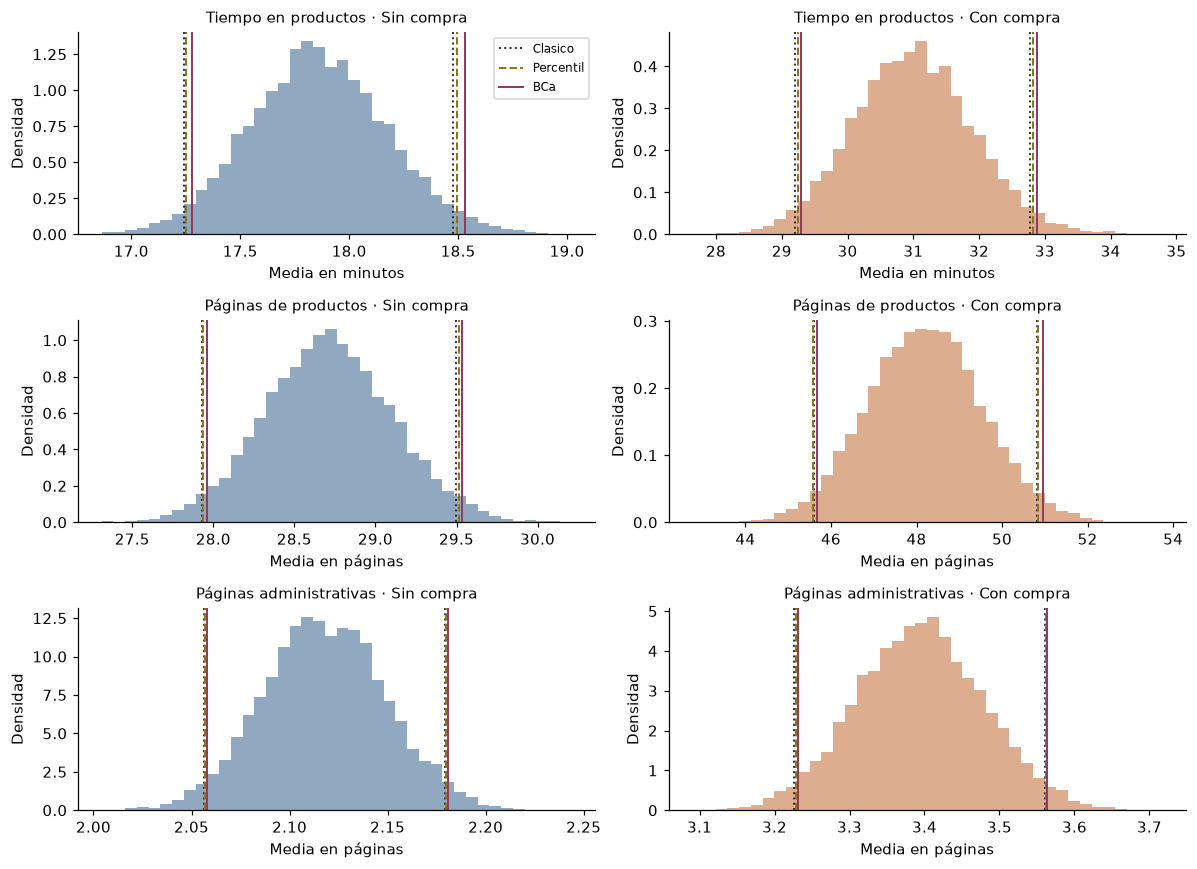

Tiempo en productos, Sin compra: amplitud BCa/clásico = 1.012; z0 = 0.021; aceleración = 0.0157.
Tiempo en productos, Con compra: amplitud BCa/clásico = 1.004; z0 = 0.003; aceleración = 0.0133.
Páginas de productos, Sin compra: amplitud BCa/clásico = 1.006; z0 = 0.022; aceleración = 0.0077.
Páginas de productos, Con compra: amplitud BCa/clásico = 1.008; z0 = 0.008; aceleración = 0.0124.
Páginas administrativas, Sin compra: amplitud BCa/clásico = 1.002; z0 = 0.014; aceleración = 0.0034.
Páginas administrativas, Con compra: amplitud BCa/clásico = 0.992; z0 = 0.001; aceleración = 0.0055.


In [6]:
fig, ejes = plt.subplots(3, 2, figsize=(11, 8))
for eje, (_, f) in zip(ejes.flat, bootstrap_medias.iterrows()):
    eje.hist(distribuciones_medias[(f.Variable,f.Grupo)], bins=40,
             color=COLORES[f.Grupo], alpha=0.55, density=True)
    for metodo, color, estilo in [('Clasico','#333333',':'),('Percentil','#8C741A','--'),('BCa','#933A5C','-')]:
        eje.axvline(f[f'{metodo}_inf'], color=color, ls=estilo, lw=1.3, label=metodo)
        eje.axvline(f[f'{metodo}_sup'], color=color, ls=estilo, lw=1.3)
    eje.set_title(f'{f.Nombre} · {f.Grupo}', fontsize=10)
    eje.set_xlabel('Media en minutos' if f.Variable=='Tiempo_minutos' else 'Media en páginas')
    eje.set_ylabel('Densidad')
ejes[0,0].legend(fontsize=8)
plt.tight_layout()
guardar_figura('01_bootstrap_medias')
for _, f in bootstrap_medias.iterrows():
    print(f'{f.Nombre}, {f.Grupo}: amplitud BCa/clásico = {f.Ancho_relativo_BCa:.3f}; '
          f'z0 = {f.z0:.3f}; aceleración = {f.Aceleracion:.4f}.')

### 2.2 Medianas de tiempo como complemento

La retroalimentación de S1 propone bootstrap de medianas por la asimetría. Calculamos intervalos percentil para las dos medianas de tiempo ya descritas en S1, con 10.000 remuestras por grupo. Este complemento describe la sesión central; no reemplaza la validación de los seis intervalos de medias. No se fabrica un intervalo clásico de mediana que no existía en S1.

,Grupo,Mediana,IC_inf,IC_sup,B,Semilla
0,Sin compra,8.4556,8.1267,8.8793,10000,142
1,Con compra,18.3011,16.9303,19.5204,10000,143


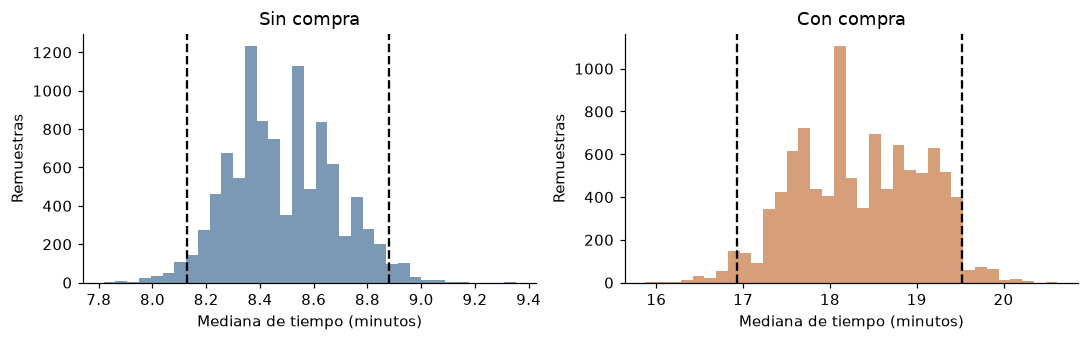

Las medianas representan un parámetro distinto de las medias; se interpretan por separado.


In [7]:
filas = []
fig, ejes = plt.subplots(1, 2, figsize=(10,3.2))
for i,(eje,grupo) in enumerate(zip(ejes,GRUPOS)):
    x = df.loc[df.Grupo==grupo, 'Tiempo_minutos'].dropna().to_numpy()
    replicas = bootstrap_estadistico(x, np.median, 142+i)
    lo, hi = np.quantile(replicas,[0.025,0.975])
    filas.append({'Grupo':grupo,'Mediana':np.median(x),'IC_inf':lo,'IC_sup':hi,'B':B,'Semilla':142+i})
    eje.hist(replicas,bins=35,color=COLORES[grupo],alpha=0.65)
    eje.axvline(lo,color='black',ls='--'); eje.axvline(hi,color='black',ls='--')
    eje.set(title=grupo,xlabel='Mediana de tiempo (minutos)',ylabel='Remuestras')
medianas = pd.DataFrame(filas)
display(medianas.round(4)); guardar_tabla('medianas',medianas)
plt.tight_layout(); guardar_figura('02_medianas')
print('Las medianas representan un parámetro distinto de las medias; se interpretan por separado.')

## 3 Validación de las pruebas de hipótesis mediante permutación

En la Sumativa 1 utilizamos la prueba t de Welch para evaluar si existen diferencias significativas entre las medias de sesiones con compra y sin compra.

Para validar esos resultados aplicamos una prueba de permutación, siguiendo la metodología estudiada en el curso.

El procedimiento consiste en:
1. Calcular el estadístico t observado utilizando los datos originales.
2. Combinar los datos de ambos grupos.
3. Redistribuir aleatoriamente las observaciones entre los dos grupos, manteniendo sus tamaños.
4. Calcular nuevamente el estadístico t.
5. Repetir el procedimiento 10.000 veces.
6. Calcular el valor p de permutación y compararlo con el obtenido mediante Welch.

La hipótesis nula establece que no existen diferencias entre las medias de ambos grupos. Utilizamos un nivel de significancia de 0,05.

$H_0:\mu_{con}-\mu_{sin}=0$, y $\alpha=0.05$

El valor p de permutación se calcula a partir de la proporción de estadísticas simuladas tan extremas como la observada, incorporando una corrección para evitar reportar un valor p igual a cero.

En este estudio se mantiene Welch como prueba principal. La permutación se utiliza como validación complementaria, considerando que la interpretación requiere supuestos sobre la posibilidad de intercambiar las observaciones entre grupos.


,Variable,Nombre,Diferencia,t,p_Welch,Extremos,p_permutacion,B,Semilla,Decision
0,Tiempo_minutos,Tiempo en productos,13.132888,13.630186,1.256785e-40,0,0.0001,10000,242,Rechazar H0
1,ProductRelated,Páginas de productos,19.495526,14.001714,8.834785e-43,0,0.0001,10000,243,Rechazar H0


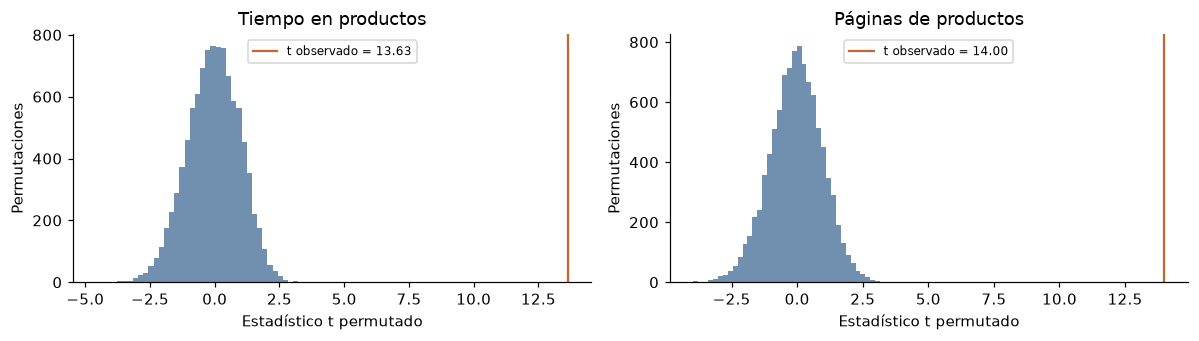

Se compara la decisión y la magnitud de las diferencias; la resolución Monte Carlo no permite reproducir valores p del orden de 10^-40.


In [8]:
def t_welch(a,b):
    return (a.mean()-b.mean())/np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))

filas, distribuciones_perm = [], {}
for i, variable in enumerate(VARIABLES[:2]):
    con = df.loc[df.Grupo=='Con compra',variable].dropna().to_numpy(dtype=float)
    sin = df.loc[df.Grupo=='Sin compra',variable].dropna().to_numpy(dtype=float)
    todos = np.concatenate([con,sin]); n_con = len(con)
    observado = t_welch(con,sin)
    clasico = stats.ttest_ind(con,sin,equal_var=False,alternative='two-sided')
    assert np.isclose(observado,clasico.statistic)
    rng = np.random.default_rng(242+i)
    replicas = np.empty(B)
    for j in range(B):
        mezcla = rng.permutation(todos)
        replicas[j] = t_welch(mezcla[:n_con],mezcla[n_con:])
    extremos = int(np.sum(np.abs(replicas)>=abs(observado)))
    p_perm = (extremos+1)/(B+1)
    filas.append({'Variable':variable,'Nombre':NOMBRES[variable],
                  'Diferencia':con.mean()-sin.mean(),'t':observado,
                  'p_Welch':clasico.pvalue,'Extremos':extremos,'p_permutacion':p_perm,
                  'B':B,'Semilla':242+i,'Decision':'Rechazar H0' if p_perm<ALFA else 'No rechazar H0'})
    distribuciones_perm[variable] = replicas
permutacion = pd.DataFrame(filas)
display(permutacion)
guardar_tabla('permutacion',permutacion)
fig,ejes=plt.subplots(1,2,figsize=(11,3.2))
for eje,(_,f) in zip(ejes,permutacion.iterrows()):
    eje.hist(distribuciones_perm[f.Variable],bins=40,color='#35618D',alpha=0.7)
    eje.axvline(f.t,color='#C06A31',label=f't observado = {f.t:.2f}')
    eje.set(title=f.Nombre,xlabel='Estadístico t permutado',ylabel='Permutaciones'); eje.legend(fontsize=8)
plt.tight_layout(); guardar_figura('03_permutacion')
print('Se compara la decisión y la magnitud de las diferencias; la resolución Monte Carlo no permite reproducir valores p del orden de 10^-40.')

## 4 Estabilidad de las tres correlaciones de S1

Para evaluar si las correlaciones identificadas en la Sumativa 1 son estables, aplicamos bootstrap con 10.000 remuestras y calculamos intervalos de confianza al 95%. 
En cada remuestra seleccionamos filas completas con reemplazo, manteniendo juntas las observaciones de ambas variables para conservar su relación.
Utilizamos el coeficiente de correlación de Pearson, que permite medir la dirección y la intensidad de la relación lineal entre dos variables.

Para evaluar la estabilidad consideramos:
- **Signo:** si la correlación se mantiene positiva o negativa.
- **Amplitud del intervalo:** qué tanta incertidumbre presenta la estimación.
- **Inclusión del cero:** si el intervalo incluye cero, no podemos descartar una correlación poblacional nula con este procedimiento.

También analizaremos si los valores extremos influyen en las correlaciones, ya que una asociación estadísticamente significativa no necesariamente es robusta frente a cambios en los datos.

,X,Y,Relacion,n,r,IC_inf,IC_sup,Ancho,SE_bootstrap,Incluye_cero,B,Semilla
0,Tiempo_minutos,ProductRelated,Tiempo en productos / Páginas de productos,11097,0.8584,0.8235,0.8861,0.0627,0.0172,False,10000,342
1,Tiempo_minutos,Administrative,Tiempo en productos / Páginas administrativas,11097,0.3717,0.3332,0.4063,0.0731,0.0187,False,10000,343
2,ProductRelated,Administrative,Páginas de productos / Páginas administrativas,11097,0.4289,0.4052,0.4531,0.0479,0.0122,False,10000,344


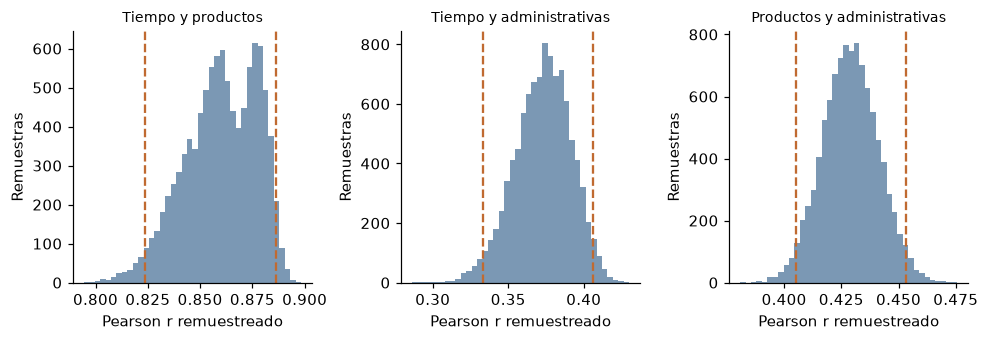

Tiempo en productos / Páginas de productos: IC [0.823, 0.886], ancho 0.063; incluye cero: False.
Tiempo en productos / Páginas administrativas: IC [0.333, 0.406], ancho 0.073; incluye cero: False.
Páginas de productos / Páginas administrativas: IC [0.405, 0.453], ancho 0.048; incluye cero: False.


In [9]:
pares = [('Tiempo_minutos','ProductRelated'),('Tiempo_minutos','Administrative'),('ProductRelated','Administrative')]
filas, distribuciones_corr = [], []

# Bootstrap para evaluar la estabilidad de correlaciones:
# 1. Seleccionar filas completas con reemplazo.
# 2. Calcular Pearson en cada remuestra.
# 3. Repetir 10.000 veces.
# 4. Obtener los percentiles 2,5 y 97,5 para el IC del 95%.
#
# Se usa una fórmula vectorizada de Pearson para procesar
# varias remuestras a la vez, sin cambiar el cálculo estadístico.
for i,(a,b) in enumerate(pares):
    x,y = completos[a].to_numpy(dtype=float),completos[b].to_numpy(dtype=float)
    rng = np.random.default_rng(342+i); replicas=np.empty(B)
    for inicio in range(0,B,64):
        cantidad=min(64,B-inicio); indices=rng.integers(0,len(x),(cantidad,len(x)))
        xx,yy=x[indices],y[indices]
        xx=xx-xx.mean(axis=1,keepdims=True); yy=yy-yy.mean(axis=1,keepdims=True)
        replicas[inicio:inicio+cantidad] = np.sum(xx*yy,axis=1)/np.sqrt(np.sum(xx*xx,axis=1)*np.sum(yy*yy,axis=1))
    lo,hi=np.quantile(replicas,[0.025,0.975])
    filas.append({'X':a,'Y':b,'Relacion':NOMBRES[a]+' / '+NOMBRES[b],
                  'n':len(x),'r':np.corrcoef(x,y)[0,1],'IC_inf':lo,'IC_sup':hi,
                  'Ancho':hi-lo,'SE_bootstrap':replicas.std(ddof=1),'Incluye_cero':bool(lo<=0<=hi),
                  'B':B,'Semilla':342+i})
    distribuciones_corr.append(replicas)
correlaciones=pd.DataFrame(filas)
assert np.allclose(correlaciones.r,[0.858,0.372,0.429],atol=0.001)
display(correlaciones.round(4)); guardar_tabla('correlaciones',correlaciones)
fig,ejes=plt.subplots(1,3,figsize=(9,3.2))
for eje,(i,f),replicas in zip(ejes,correlaciones.iterrows(),distribuciones_corr):
    eje.hist(replicas,bins=40,color='#35618D',alpha=0.65)
    eje.axvline(f.IC_inf,color='#C06A31',ls='--'); eje.axvline(f.IC_sup,color='#C06A31',ls='--')
    eje.set_title(['Tiempo y productos', 'Tiempo y administrativas', 'Productos y administrativas'][i],fontsize=9)
    eje.set(xlabel='Pearson r remuestreado',ylabel='Remuestras')
plt.tight_layout(); guardar_figura('04_correlaciones')
for _,f in correlaciones.iterrows():
    print(f'{f.Relacion}: IC [{f.IC_inf:.3f}, {f.IC_sup:.3f}], ancho {f.Ancho:.3f}; incluye cero: {f.Incluye_cero}.')

## 5 Simulación Monte Carlo y datos sintéticos

### 5.1 Escenario y parámetros provenientes de S1

Aplicamos el método Monte Carlo para estudiar cómo podrían variar el número de compras y el tiempo total de navegación en conjuntos de 1.000 sesiones.

El objetivo es generar 10.000 escenarios posibles utilizando exclusivamente parámetros estadísticos obtenidos en la Sumativa 1.

El procedimiento considera:
1. **Definir las variables de entrada:** proporción de sesiones con compra, medias y varianzas del tiempo de navegación por grupo.
2. **Generar valores aleatorios:** simular si cada sesión termina en compra y generar su tiempo de navegación.
3. **Ejecutar el modelo:** calcular el número de compras y el tiempo total de cada conjunto de 1.000 sesiones.
4. **Repetir 10.000 veces:** obtener diferentes escenarios posibles.
5. **Analizar los resultados:** calcular medias, dispersión, percentiles y convergencia.

Para simular las compras utilizamos una distribución Bernoulli, basada en la proporción de compra observada en S1 (15,47%).

Para los tiempos de navegación utilizamos distribuciones gamma, cuyos parámetros se calculan a partir de las medias y varianzas de S1. Esta distribución permite representar tiempos positivos y asimétricos, aunque no reproduce los valores exactamente iguales a cero presentes en los datos originales.(Maidana, 2026b, 2026c)

La simulación permite estudiar posibles resultados bajo estos supuestos, pero no debe interpretarse como una predicción comercial ni como evidencia de que el tiempo de navegación cause una compra. 

In [10]:
tiempo_s1=base_s1[base_s1.Variable=='Tiempo_minutos'].set_index('Grupo').loc[GRUPOS]
mu_grupo=tiempo_s1.Media.to_numpy()
var_grupo=tiempo_s1.DE.to_numpy()**2
forma=mu_grupo**2/var_grupo
escala=var_grupo/mu_grupo
sigma_log=np.sqrt(np.log1p(var_grupo/mu_grupo**2))
mu_log=np.log(mu_grupo)-0.5*sigma_log**2
parametros_mc=pd.DataFrame({'Grupo':GRUPOS,'Media_S1':mu_grupo,'Varianza_S1':var_grupo,
                           'Gamma_forma':forma,'Gamma_escala':escala,
                           'Lognormal_mu':mu_log,'Lognormal_sigma':sigma_log})
display(parametros_mc.round(5)); guardar_tabla('parametros_mc',parametros_mc)

def simular_sesiones(n_sesiones=1000,p=p_compra,modelo='gamma',semilla=442,repeticiones=B):
    # Inicializar el generador para obtener resultados reproducibles
    rng=np.random.default_rng(semilla)
    compras=np.empty(repeticiones); minutos=np.empty(repeticiones)
    for inicio in range(0,repeticiones,100):
        cantidad=min(100,repeticiones-inicio)
        # Generar aleatoriamente sesiones con compra y sin compra
        grupo=(rng.random((cantidad,n_sesiones))<p).astype(int)
        # Simular tiempos de navegación según la distribución elegida
        if modelo=='gamma':
            tiempos=rng.gamma(forma[grupo],escala[grupo])
        elif modelo=='lognormal':
            tiempos=rng.lognormal(mu_log[grupo],sigma_log[grupo])
        else:
            raise ValueError('Modelo desconocido')
        assert np.isfinite(tiempos).all() and (tiempos>=0).all()
        # Guardar el número de compras y el tiempo total de cada simulación
        compras[inicio:inicio+cantidad]=grupo.sum(axis=1)
        minutos[inicio:inicio+cantidad]=tiempos.sum(axis=1)
    return compras,minutos

compras_mc,minutos_mc=simular_sesiones()
media_sesion=(1-p_compra)*mu_grupo[0]+p_compra*mu_grupo[1]
var_sesion=(1-p_compra)*(var_grupo[0]+mu_grupo[0]**2)+p_compra*(var_grupo[1]+mu_grupo[1]**2)-media_sesion**2

def resumen_mc(compras,minutos,n,p,modelo):
    resultado=[]
    for nombre,x,teorico,varianza in [
        ('Compras',compras,n*p,n*p*(1-p)),
        ('Tiempo total en minutos',minutos,n*((1-p)*mu_grupo[0]+p*mu_grupo[1]),
         n*((1-p)*(var_grupo[0]+mu_grupo[0]**2)+p*(var_grupo[1]+mu_grupo[1]**2)-((1-p)*mu_grupo[0]+p*mu_grupo[1])**2))]:
        lo,hi=np.quantile(x,[0.025,0.975]); se=x.std(ddof=1)/np.sqrt(len(x))
        resultado.append({'Salida':nombre,'N':n,'p':p,'Modelo':modelo,'B':len(x),
                          'Media':x.mean(),'Esperanza_teorica':teorico,'DE':x.std(ddof=1),
                          'DE_teorica':np.sqrt(varianza),'MCSE':se,
                          'P025':lo,'P975':hi,'P99':np.quantile(x,0.99),
                          'IC_media_inf':x.mean()-1.96*se,'IC_media_sup':x.mean()+1.96*se})
    return pd.DataFrame(resultado)

montecarlo=resumen_mc(compras_mc,minutos_mc,1000,p_compra,'gamma')
display(montecarlo.round(4)); guardar_tabla('montecarlo',montecarlo)
assert np.all(np.abs(montecarlo.Media-montecarlo.Esperanza_teorica)<5*montecarlo.MCSE)

,Grupo,Media_S1,Varianza_S1,Gamma_forma,Gamma_escala,Lognormal_mu,Lognormal_sigma
0,Sin compra,17.85836,931.60740,0.34233,52.16647,2.19928,1.16892
1,Con compra,30.99124,1417.78952,0.67743,45.74807,2.98035,0.95221


,Salida,N,p,Modelo,B,Media,Esperanza_teorica,DE,DE_teorica,MCSE,P025,P975,P99,IC_media_inf,IC_media_sup
0,Compras,1000,0.1547,gamma,10000,154.6970,154.7445,11.3980,11.4367,0.114,133.0000,178.0000,182.0000,154.4736,154.9204
1,Tiempo total en minutos,1000,0.1547,gamma,10000,19891.4701,19890.5987,1029.2022,1014.5938,10.292,17922.2379,21970.7381,22377.3809,19871.2977,19911.6424


### 5.2 Validación de los registros sintéticos

Generamos además 12.330 sesiones sintéticas para comparar los momentos por grupo con S1. Esta muestra sirve para examinar la fidelidad del generador, no se mezcla con los datos observados. La comparación incluye medianas y ceros para detectar aspectos que el modelo de dos momentos no reproduce. La semilla es 443.

In [11]:
rng=np.random.default_rng(443)
g=(rng.random(len(df))<p_compra).astype(int)
sinteticos=pd.DataFrame({'Revenue':g.astype(bool),'Tiempo_minutos':rng.gamma(forma[g],escala[g])})
filas=[]
for i,grupo in enumerate(GRUPOS):
    x=sinteticos.loc[sinteticos.Revenue==bool(i),'Tiempo_minutos'].to_numpy()
    filas.append({'Grupo':grupo,'n_sintetico':len(x),'Media_S1':mu_grupo[i],
                  'Media_sintetica':x.mean(),'DE_S1':np.sqrt(var_grupo[i]),'DE_sintetica':x.std(ddof=1),
                  'Mediana_S1':tiempo_s1.loc[grupo,'Mediana'],'Mediana_sintetica':np.median(x),
                  'Ceros_S1':tiempo_s1.loc[grupo,'Ceros'],'Ceros_sinteticos':np.mean(x==0)})
validacion_sinteticos=pd.DataFrame(filas)
display(validacion_sinteticos.round(4)); guardar_tabla('validacion_sinteticos',validacion_sinteticos)
print('La gamma genera tiempos positivos: la proporción de ceros no está reproducida. No se afirma equivalencia entre distribución real y sintética.')

,Grupo,n_sintetico,Media_S1,Media_sintetica,DE_S1,DE_sintetica,Mediana_S1,Mediana_sintetica,Ceros_S1,Ceros_sinteticos
0,Sin compra,10415,17.8584,17.9866,30.5222,30.8082,8.4556,5.4290,0.0709,0.0
1,Con compra,1915,30.9912,31.8120,37.6535,38.8275,18.3011,17.8922,0.0058,0.0


La gamma genera tiempos positivos: la proporción de ceros no está reproducida. No se afirma equivalencia entre distribución real y sintética.


### 5.3 Convergencia e interpretación de incertidumbre

Para evaluar la precisión de la simulación Monte Carlo analizamos cómo cambian los resultados al aumentar el número de iteraciones.

De acuerdo con la Ley de los Grandes Números, a medida que realizamos más simulaciones, la media acumulada debería estabilizarse cerca del valor esperado del modelo.Evaluamos los resultados utilizando 100, 500, 1.000, 5.000 y 10.000 iteraciones.

Calculamos:

- **Media acumulada:** permite observar si las estimaciones se estabilizan.
- **Error estándar Monte Carlo (MCSE):** mide la precisión de la media estimada mediante simulación.
- **Error relativo:** compara la media simulada con el valor esperado del modelo.

Como criterio de precisión, verificamos que la semiamplitud del intervalo de confianza de la media simulada sea inferior al 0,5% de su valor esperado.También repetimos la simulación con distintas semillas para comprobar la estabilidad de las estimaciones.

Finalmente, los percentiles 2,5 y 97,5 muestran el rango central de los resultados simulados. Este rango representa la variabilidad de los escenarios, no la incertidumbre del promedio estimado.

Una simulación puede alcanzar una buena precisión numérica sin que eso garantice que el modelo represente perfectamente la realidad.

,Salida,Iteraciones,Media,MCSE,Error_relativo,Semiamplitud_relativa
0,Compras,100,154.480000,1.144109,0.001709,0.014491
1,Compras,500,154.952000,0.488697,0.001341,0.006190
2,Compras,1000,154.454000,0.349382,0.001877,0.004425
3,Compras,5000,154.567600,0.161369,0.001143,0.002044
4,Compras,10000,154.697000,0.113980,0.000307,0.001444
5,Minutos,100,19714.789394,109.323505,0.008839,0.010773
6,Minutos,500,19898.146784,42.414913,0.000379,0.004180
7,Minutos,1000,19882.152743,31.309771,0.000425,0.003085
8,Minutos,5000,19891.090283,14.425546,0.000025,0.001421
9,Minutos,10000,19891.470062,10.292022,0.000044,0.001014


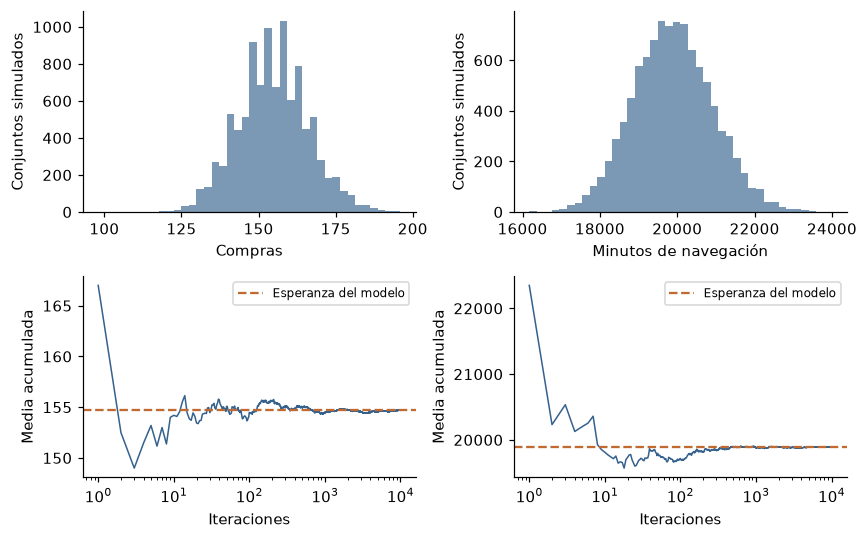

,Salida,Semilla,Media,MCSE,P025,P975
0,Compras,442,154.6970,0.1140,133.0000,178.0000
1,Tiempo total en minutos,442,19891.4701,10.2920,17922.2379,21970.7381
2,Compras,444,154.7912,0.1136,133.0000,177.0000
3,Tiempo total en minutos,444,19881.1429,10.0678,17929.5998,21920.9520
4,Compras,445,154.6422,0.1140,133.0000,177.0000
5,Tiempo total en minutos,445,19889.9158,10.1241,17939.9834,21927.0024


In [12]:
filas=[]
for nombre,x,esperanza in [('Compras',compras_mc,1000*p_compra),('Minutos',minutos_mc,1000*media_sesion)]:
    for k in [100,500,1000,5000,10000]:
        se=x[:k].std(ddof=1)/np.sqrt(k)
        filas.append({'Salida':nombre,'Iteraciones':k,'Media':x[:k].mean(),'MCSE':se,
                      'Error_relativo':abs(x[:k].mean()-esperanza)/esperanza,
                      'Semiamplitud_relativa':1.96*se/esperanza})
convergencia=pd.DataFrame(filas)
display(convergencia.round(6)); guardar_tabla('convergencia',convergencia)
assert (convergencia.loc[convergencia.Iteraciones==B,'Semiamplitud_relativa']<0.005).all()
fig,ejes=plt.subplots(2,2,figsize=(8,5))
for columna,(nombre,x,esperanza) in enumerate([('Compras',compras_mc,1000*p_compra),('Minutos de navegación',minutos_mc,1000*media_sesion)]):
    ejes[0,columna].hist(x,bins=40,color='#35618D',alpha=0.65)
    ejes[0,columna].set(xlabel=nombre,ylabel='Conjuntos simulados')
    ejes[0,columna].locator_params(axis='x',nbins=5)
    k=np.arange(1,B+1); acumulada=np.cumsum(x)/k
    ejes[1,columna].plot(k,acumulada,color='#35618D',lw=1)
    ejes[1,columna].axhline(esperanza,color='#C06A31',ls='--',label='Esperanza del modelo')
    ejes[1,columna].set(xscale='log',xlabel='Iteraciones',ylabel='Media acumulada'); ejes[1,columna].legend(fontsize=8)
plt.tight_layout(); guardar_figura('05_montecarlo')
repeticiones_semilla=[]
for semilla in [442,444,445]:
    if semilla==442: c,t=compras_mc,minutos_mc
    else: c,t=simular_sesiones(semilla=semilla)
    tabla=resumen_mc(c,t,1000,p_compra,'gamma'); tabla['Semilla']=semilla
    repeticiones_semilla.append(tabla)
estabilidad_semillas=pd.concat(repeticiones_semilla,ignore_index=True)
display(estabilidad_semillas[['Salida','Semilla','Media','MCSE','P025','P975']].round(4))
guardar_tabla('estabilidad_semillas',estabilidad_semillas)

### 5.4 Sensibilidad a entradas y supuestos

El análisis de sensibilidad permite evaluar cómo cambian los resultados de la simulación cuando modificamos sus condiciones iniciales.

Para ello, estudiamos tres tipos de escenarios:
1. **Cantidad de sesiones:** comparamos conjuntos de 100, 1.000 y 5.000 sesiones.
2. **Proporción de compras:** simulamos una disminución y un aumento relativo del 10% respecto de la proporción observada en S1.
3. **Distribución estadística:** comparamos los resultados utilizando distribuciones gamma y lognormal, manteniendo las medias y varianzas estimadas previamente.

En cada escenario realizamos 10.000 simulaciones, modificando una condición a la vez. El objetivo es identificar qué factores producen cambios importantes en los resultados y cuáles mantienen estimaciones relativamente estables. Los escenarios son hipotéticos y permiten estudiar la sensibilidad del modelo, pero no representan predicciones de mejoras comerciales ni relaciones causales.

,Escenario,Salida,N,p,Media,P025,P975,P99
0,Base,Compras,1000,0.155,154.697,133.000,178.000,182.000
1,Base,Tiempo total en minutos,1000,0.155,19891.470,17922.238,21970.738,22377.381
2,100 sesiones,Compras,100,0.155,15.510,9.000,23.000,24.000
3,100 sesiones,Tiempo total en minutos,100,0.155,1995.285,1417.585,2684.842,2820.006
4,5000 sesiones,Compras,5000,0.155,773.901,723.000,825.000,834.000
5,5000 sesiones,Tiempo total en minutos,5000,0.155,99455.983,95115.743,103981.820,104836.264
6,Compra -10% relativo,Compras,1000,0.139,139.255,118.000,161.000,165.000
7,Compra -10% relativo,Tiempo total en minutos,1000,0.139,19693.377,17781.927,21692.261,22044.813
8,Compra +10% relativo,Compras,1000,0.170,170.000,147.000,194.000,198.000
9,Compra +10% relativo,Tiempo total en minutos,1000,0.170,20092.110,18170.249,22105.762,22528.936


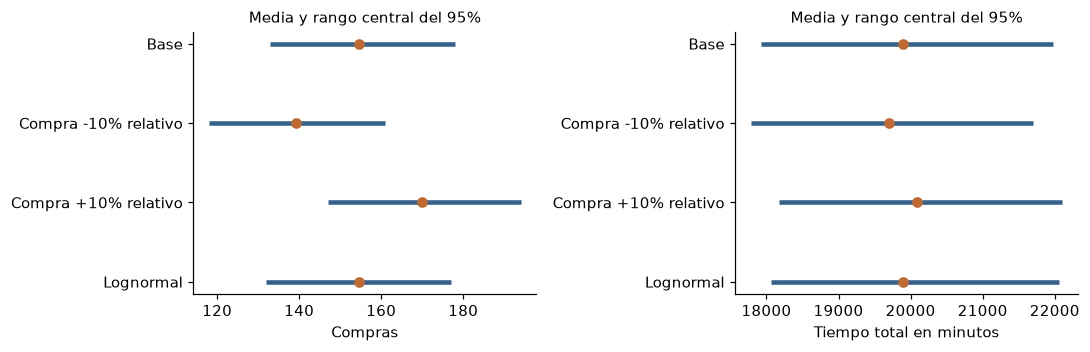

In [13]:
escenarios=[('Base',1000,p_compra,'gamma',442),
            ('100 sesiones',100,p_compra,'gamma',452),
            ('5000 sesiones',5000,p_compra,'gamma',453),
            ('Compra -10% relativo',1000,p_compra*0.9,'gamma',454),
            ('Compra +10% relativo',1000,p_compra*1.1,'gamma',455),
            ('Lognormal',1000,p_compra,'lognormal',456)]
tablas=[]
for nombre,n,p,modelo,semilla in escenarios:
    if nombre=='Base':c,t=compras_mc,minutos_mc
    else:c,t=simular_sesiones(n,p,modelo,semilla)
    tabla=resumen_mc(c,t,n,p,modelo); tabla['Escenario']=nombre; tabla['Semilla']=semilla
    tablas.append(tabla)
sensibilidad=pd.concat(tablas,ignore_index=True)
display(sensibilidad[['Escenario','Salida','N','p','Media','P025','P975','P99']].round(3))
guardar_tabla('sensibilidad_mc',sensibilidad)
fig,ejes=plt.subplots(1,2,figsize=(10,3.3))
for eje,salida in zip(ejes,['Compras','Tiempo total en minutos']):
    s=sensibilidad[(sensibilidad.Salida==salida)&(sensibilidad.N==1000)]
    y=np.arange(len(s))
    eje.hlines(y,s.P025,s.P975,color='#35618D',lw=3)
    eje.scatter(s.Media,y,color='#C06A31',zorder=3)
    eje.set_yticks(y,s.Escenario); eje.invert_yaxis(); eje.set_xlabel(salida)
    eje.set_title('Media y rango central del 95%',fontsize=10)
plt.tight_layout(); guardar_figura('06_sensibilidad')

## 6 Robustez frente a valores extremos

### 6.1 Medias e influencia individual mediante jackknife

Los valores extremos pueden afectar las medias y las conclusiones estadísticas. Para evaluar su influencia comparamos los resultados originales con estimaciones alternativas.

Utilizamos cuatro procedimientos:
1. **Media original:** referencia obtenida en S1.
2. **Mediana:** medida de tendencia central menos sensible a valores extremos.
3. **Media recortada:** excluye el 5% de los valores más bajos y el 5% de los más altos.
4. **Exclusión del 1% superior:** permite evaluar cuánto cambian los resultados al retirar los valores más elevados.

Además, aplicamos jackknife, que consiste en recalcular la media excluyendo una observación a la vez, para identificar sesiones con mayor influencia individual.

Si los resultados cambian considerablemente, significa que la estimación es sensible a los valores extremos. Si se mantienen similares, existe mayor evidencia de robustez.

Estas comparaciones son exploratorias y no implican eliminar permanentemente registros de la base de datos.

In [14]:
filas=[]
for _,f in base_s1.iterrows():
    serie=df.loc[df.Grupo==f.Grupo,f.Variable].dropna()
    x=serie.to_numpy(dtype=float); n=len(x)
    jack=(x.sum()-x)/(n-1); cambios=jack-x.mean(); j=int(np.argmax(np.abs(cambios)))
    recortada=stats.trim_mean(x,0.05); limite=np.quantile(x,0.99)
    sin_superior=x[x<=limite].mean()
    se=np.sqrt((n-1)/n*np.sum((jack-jack.mean())**2))
    assert np.isclose(se,x.std(ddof=1)/np.sqrt(n))
    filas.append({'Variable':f.Variable,'Nombre':f.Nombre,'Grupo':f.Grupo,'Media':x.mean(),
                  'Mediana':np.median(x),'Recortada_5':recortada,'Sin_1_superior':sin_superior,
                  'Cambio_recortada_pct':100*(recortada/x.mean()-1),
                  'Cambio_sin_superior_pct':100*(sin_superior/x.mean()-1),
                  'Jackknife_SE':se,'Fila_influyente':int(serie.index[j]),
                  'Valor_influyente':x[j],'Media_sin_influyente':jack[j],
                  'Cambio_individual':cambios[j]})
robustez=pd.DataFrame(filas)
display(robustez.round(4)); guardar_tabla('robustez_medias',robustez)

,Variable,Nombre,Grupo,Media,Mediana,Recortada_5,Sin_1_superior,Cambio_recortada_pct,Cambio_sin_superior_pct,Jackknife_SE,Fila_influyente,Valor_influyente,Media_sin_influyente,Cambio_individual
0,Tiempo_minutos,Tiempo en productos,Sin compra,17.8584,8.4556,13.6714,15.9507,-23.4455,-10.6821,0.3150,8071,1066.2254,17.7467,-0.1117
1,Tiempo_minutos,Tiempo en productos,Con compra,30.9912,18.3011,25.8600,28.8245,-16.5571,-6.9915,0.9106,8784,450.1643,30.7460,-0.2453
2,ProductRelated,Páginas de productos,Sin compra,28.7146,16.0000,22.8918,26.0929,-20.2783,-9.1305,0.3991,5152,705.0000,28.6497,-0.0649
3,ProductRelated,Páginas de productos,Con compra,48.2102,29.0000,40.0122,44.6695,-17.0046,-7.3443,1.3339,10318,534.0000,47.9554,-0.2547
4,Administrative,Páginas administrativas,Sin compra,2.1177,0.0000,1.6952,1.9919,-19.9520,-5.9431,0.0314,8308,27.0000,2.1153,-0.0024
5,Administrative,Páginas administrativas,Con compra,3.3936,2.0000,3.0099,3.2472,-11.3069,-4.3136,0.0854,12178,26.0000,3.3818,-0.0119


### 6.2 Sensibilidad de correlaciones y contrastes

Para evaluar la influencia de los valores extremos sobre las correlaciones de Pearson, comparamos los resultados originales con los obtenidos después de excluir el 1% superior de cualquiera de las dos variables analizadas.También aplicamos jackknife para identificar la observación que genera el mayor cambio individual en cada correlación.

Posteriormente repetimos las pruebas t de Welch, excluyendo el 1% superior de cada grupo, y comparamos las diferencias de medias y los valores p con los resultados originales. El objetivo es determinar si las conclusiones estadísticas se mantienen al modificar los datos de forma controlada. Si una conclusión cambia considerablemente, se considera sensible a los valores extremos y requiere mayor precaución en su interpretación.

Estas modificaciones se utilizan solamente para el análisis de robustez y no reemplazan los datos originales de S1.

In [15]:
filas=[]
for a,b in pares:
    x=completos[a].to_numpy(dtype=float); y=completos[b].to_numpy(dtype=float); n=len(x)
    sx,sy=x.sum()-x,y.sum()-y
    sxx,syy=(x*x).sum()-x*x,(y*y).sum()-y*y
    sxy=(x*y).sum()-x*y
    jack=(sxy-sx*sy/(n-1))/np.sqrt((sxx-sx*sx/(n-1))*(syy-sy*sy/(n-1)))
    r=np.corrcoef(x,y)[0,1]; j=int(np.argmax(np.abs(jack-r)))
    mascara=(x<=np.quantile(x,0.99))&(y<=np.quantile(y,0.99))
    rt=np.corrcoef(x[mascara],y[mascara])[0,1]
    filas.append({'X':a,'Y':b,'r_original':r,'r_sin_superiores':rt,'n_alternativo':int(mascara.sum()),
                  'Cambio_r':rt-r,'Fila_influyente':int(completos.index[j]),
                  'r_sin_influyente':jack[j],'Cambio_individual':jack[j]-r})
robustez_corr=pd.DataFrame(filas)
display(robustez_corr.round(4)); guardar_tabla('robustez_correlaciones',robustez_corr)
filas=[]
for variable in VARIABLES[:2]:
    con=df.loc[df.Grupo=='Con compra',variable].dropna().to_numpy()
    sin=df.loc[df.Grupo=='Sin compra',variable].dropna().to_numpy()
    a=con[con<=np.quantile(con,0.99)]; b=sin[sin<=np.quantile(sin,0.99)]
    prueba=stats.ttest_ind(a,b,equal_var=False)
    filas.append({'Variable':variable,'Diferencia_original':con.mean()-sin.mean(),
                  'Diferencia_alternativa':a.mean()-b.mean(),'n_con':len(a),'n_sin':len(b),
                  't_alternativo':prueba.statistic,'p_alternativo':prueba.pvalue})
robustez_pruebas=pd.DataFrame(filas)
display(robustez_pruebas); guardar_tabla('robustez_pruebas',robustez_pruebas)

,X,Y,r_original,r_sin_superiores,n_alternativo,Cambio_r,Fila_influyente,r_sin_influyente,Cambio_individual
0,Tiempo_minutos,ProductRelated,0.8584,0.8347,10953,-0.0237,8071,0.8772,0.0188
1,Tiempo_minutos,Administrative,0.3717,0.3504,10900,-0.0213,8071,0.3884,0.0167
2,ProductRelated,Administrative,0.4289,0.4055,10899,-0.0234,8308,0.4246,-0.0043


,Variable,Diferencia_original,Diferencia_alternativa,n_con,n_sin,t_alternativo,p_alternativo
0,Tiempo_minutos,13.132888,12.873800,1692,9293,16.582586,6.406043e-58
1,ProductRelated,19.495526,18.576635,1888,10317,16.665766,8.653094e-59


## 7 Evaluación controlada de los faltantes MCAR

En la Sumativa 1 se generaron valores faltantes de manera completamente aleatoria (MCAR), conservando un respaldo de los valores originales.
Este respaldo permite evaluar cuánto influyen los datos faltantes en los resultados estadísticos.

Primero comparamos las medias calculadas con los datos disponibles y las medias obtenidas con la base completa.
Luego evaluamos dos métodos sencillos de imputación:

- **Imputación por media:** reemplaza los valores faltantes por la media de los datos observados.
- **Imputación por mediana:** reemplaza los valores faltantes por la mediana de los datos observados.

Para comparar los métodos utilizamos MAE (error absoluto medio) y RMSE (raíz del error cuadrático medio), considerando únicamente las 1.233 posiciones cuyos valores originales conocemos. Estos indicadores permiten identificar qué método aproxima mejor los valores ocultados según el criterio utilizado.

La comparación es un experimento controlado y no implica seleccionar automáticamente alguno de los métodos para las siguientes etapas del proyecto.

In [16]:
filas=[]
for grupo in GRUPOS:
    mascara=df.Grupo==grupo
    observado=df.loc[mascara,'Tiempo_minutos'].dropna()
    completo=original.loc[mascara,'ProductRelated_Duration']/60
    filas.append({'Grupo':grupo,'Media_observada':observado.mean(),'Media_completa':completo.mean(),
                  'Diferencia':observado.mean()-completo.mean(),
                  'Cambio_pct':100*(observado.mean()/completo.mean()-1)})
evaluacion_mcar=pd.DataFrame(filas)
display(evaluacion_mcar.round(5)); guardar_tabla('evaluacion_mcar',evaluacion_mcar)
verdad=respaldo.valor_original.to_numpy()/60
media_completa=(original.ProductRelated_Duration/60).mean()
filas=[]
for nombre,valor in [('Media global',df.Tiempo_minutos.mean()),('Mediana global',df.Tiempo_minutos.median())]:
    estimada=np.full(len(verdad),valor)
    reconstruida=df.Tiempo_minutos.fillna(valor)
    filas.append({'Metodo':nombre,'Relleno':valor,'n_evaluados':len(verdad),
                  'MAE':np.mean(np.abs(estimada-verdad)),
                  'RMSE':np.sqrt(np.mean((estimada-verdad)**2)),
                  'Media_reconstruida':reconstruida.mean(),'Media_completa':media_completa,
                  'Cambio_media_pct':100*(reconstruida.mean()/media_completa-1)})
imputacion=pd.DataFrame(filas)
display(imputacion.round(4)); guardar_tabla('evaluacion_imputacion',imputacion)
print('La base principal sigue sin imputación:',df.Tiempo_minutos.isna().sum(),'faltantes.')
assert df.Tiempo_minutos.isna().sum()==1233

,Grupo,Media_observada,Media_completa,Diferencia,Cambio_pct
0,Sin compra,17.85836,17.83313,0.02523,0.14146
1,Con compra,30.99124,31.27016,-0.27892,-0.89196


,Metodo,Relleno,n_evaluados,MAE,RMSE,Media_reconstruida,Media_completa,Cambio_media_pct
0,Media global,19.8821,1233,18.5197,30.2093,19.8821,19.9124,-0.1525
1,Mediana global,9.9606,1233,16.5609,31.8914,18.8899,19.9124,-5.1350


La base principal sigue sin imputación: 1233 faltantes.


## 8 Resultados validados y recomendaciones para S3

### Síntesis de los principales resultados

**1. Validación de los intervalos de confianza**

Los intervalos BCa presentaron amplitudes muy similares a los intervalos clásicos de S1, con diferencias entre un 0,81% menos y un 1,23% más. Esto indica que las estimaciones de las medias muestran una precisión similar al utilizar ambos métodos. Sin embargo, la similitud de los intervalos no elimina la posible influencia de los valores extremos.

**2. Comparación de medias y medianas**

El tiempo medio de navegación fue de 17,86 minutos en sesiones sin compra y 30,99 minutos en sesiones con compra. Las medianas fueron de 8,46 y 18,30 minutos, respectivamente. Las medianas considerablemente inferiores a las medias muestran que las distribuciones son asimétricas, por lo que resulta conveniente presentar ambas medidas.

**3. Validación de las pruebas de hipótesis**

Las pruebas de permutación confirmaron las conclusiones obtenidas previamente mediante Welch. En las 10.000 permutaciones no se observaron estadísticas tan extremas como las originales. Aplicando la corrección correspondiente, el valor p estimado fue de 1/10.001, aproximadamente 0,0001. Por lo tanto, se mantiene evidencia estadística de diferencias entre las sesiones con compra y sin compra para las variables analizadas. Esta conclusión también se conserva al excluir el 1% superior.

**4. Estabilidad de correlaciones**

Los intervalos bootstrap de las tres correlaciones fueron positivos, lo que respalda la dirección de las asociaciones identificadas en S1.
La relación más fuerte corresponde al tiempo de navegación y la cantidad de páginas de productos visitadas (r = 0,858).
Esta correlación elevada indica que ambas variables contienen información relacionada, aspecto que deberá revisarse en S3 para evitar problemas de redundancia.

**5. Resultados de la simulación Monte Carlo**

Al simular conjuntos de 1.000 sesiones, se obtuvo un promedio de 154,70 compras y 19.891,47 minutos de navegación acumulados.
El rango central del 95% de los resultados simulados fue de 133 a 178 compras y de 17.922,24 a 21.970,74 minutos.
La precisión numérica alcanzada cumplió el criterio establecido, con semiamplitudes relativas de 0,144% y 0,101%, inferiores al límite del 0,5%.
Estos resultados muestran el comportamiento esperado de los escenarios bajo los supuestos del modelo.

**6. Evaluación de datos sintéticos**

La distribución gamma permitió aproximar las medias y desviaciones estándar, pero presentó diferencias en otras características de los datos.
Por ejemplo, la mediana sintética del grupo sin compra fue de 5,43 minutos, frente a una mediana observada de 8,46 minutos. Además, el modelo gamma no reproduce los tiempos iguales a cero.
Esto indica que los datos sintéticos permiten explorar escenarios, pero no representan perfectamente todas las características de los datos originales.

**7. Análisis de robustez**

Al excluir el 1% de los valores superiores, las seis medias disminuyeron entre un 4,31% y un 10,68%.
Las correlaciones también disminuyeron ligeramente, entre 0,021 y 0,024 puntos.
Esto demuestra que los valores extremos afectan la magnitud de algunas estimaciones, aunque las principales conclusiones estadísticas se mantienen.

**8. Evaluación de datos faltantes**

Las medias calculadas con datos disponibles presentaron diferencias pequeñas respecto de la base completa: +0,14% en sesiones sin compra y −0,89% en sesiones con compra.
La imputación por mediana produjo menor MAE, mientras que la imputación por media obtuvo menor RMSE.
Por lo tanto, ninguno de los métodos resulta automáticamente superior: su elección depende del objetivo del análisis.

### Recomendaciones para la Sumativa 3

A partir de los resultados obtenidos, se recomienda:
- Mantener las medias acompañadas de medianas e intervalos de confianza, especialmente en variables asimétricas.
- Revisar la influencia de los valores extremos antes de decidir su tratamiento.
- Considerar la elevada correlación entre tiempo de navegación y páginas de productos al seleccionar variables para futuros modelos.
- Considerar el desbalance entre sesiones con compra y sin compra.
- Incorporar variables adicionales, como mes y tipo de visitante, para profundizar el análisis.
- Evaluar cuidadosamente los métodos de imputación antes de utilizarlos en modelos predictivos.

En conclusión, los procedimientos bootstrap, permutación y Monte Carlo aportaron evidencia adicional sobre la estabilidad y precisión de los resultados de S1. Sin embargo, algunas estimaciones presentan sensibilidad a valores extremos y los modelos de simulación tienen limitaciones que deben considerarse en la siguiente etapa.


In [17]:
# Preparación de resultados validados para la Sumativa 3
#
# Reunimos los resultados obtenidos mediante:
# 1. Bootstrap: precisión de las medias e intervalos BCa.
# 2. Permutación: validación de las pruebas de hipótesis.
# 3. Correlaciones: estabilidad de las relaciones.
# 4. Monte Carlo: resultados de los escenarios simulados.
#
# Para cada análisis registramos la evidencia estadística
# y una recomendación para la siguiente fase del proyecto.

filas=[]
for _,f in bootstrap_medias.iterrows():
    r=robustez[(robustez.Variable==f.Variable)&(robustez.Grupo==f.Grupo)].iloc[0]
    filas.append({'Bloque':'Media','Resultado':f.Nombre+' · '+f.Grupo,
                  'Estimacion':f.Media,'Inferior':f.BCa_inf,'Superior':f.BCa_sup,
                  'Fila_influyente':int(r.Fila_influyente),'Cambio_individual':r.Cambio_individual,
                  'Cambio_exclusion_pct':r.Cambio_sin_superior_pct,
                  'Estado':'Media estable entre métodos, pero sensible a valores extremos',
                  'Evidencia':f'BCa con {B} remuestras; cambio al retirar 1% superior: {r.Cambio_sin_superior_pct:.2f}%.',
                  'Recomendacion':'Conservar media con su IC; acompañar con mediana e IQR.'})
for _,f in permutacion.iterrows():
    alternativa=robustez_pruebas[robustez_pruebas.Variable==f.Variable].iloc[0]
    coincide=(f.p_Welch<ALFA)==(f.p_permutacion<ALFA)==(alternativa.p_alternativo<ALFA)
    filas.append({'Bloque':'Contraste','Resultado':f.Nombre,'Estimacion':f.Diferencia,
                  'Estado':'Decisión estable en las comparaciones evaluadas' if coincide else 'Revisar discrepancia',
                  'Evidencia':f'p Welch={f.p_Welch:.3e}; p permutación={f.p_permutacion:.6f}; diferencia alternativa={alternativa.Diferencia_alternativa:.3f}.',
                  'Recomendacion':'Interpretar asociación y magnitud; no causalidad.'})
for i,f in correlaciones.iterrows():
    r=robustez_corr.iloc[i]
    filas.append({'Bloque':'Correlación','Resultado':f.Relacion,'Estimacion':f.r,
                  'Inferior':f.IC_inf,'Superior':f.IC_sup,
                  'Fila_influyente':int(r.Fila_influyente),'Cambio_individual':r.Cambio_individual,
                  'Estado':'Correlación positiva estable; revisar valores extremos' if not f.Incluye_cero else 'Signo incierto',
                  'Evidencia':f'IC percentil; r alternativo={r.r_sin_superiores:.3f}; fila influyente={int(r.Fila_influyente)}.',
                  'Recomendacion':'Considerar redundancia y evaluar influencia antes de modelar.'})
filas.append({'Bloque':'Monte Carlo','Resultado':'1000 sesiones comparables',
              'Estimacion':montecarlo.loc[montecarlo.Salida=='Compras','Media'].iloc[0],
              'Estado':'Simulación estable bajo los supuestos del modelo',
              'Evidencia':f'{B} iteraciones por escenario; sensibilidad de entradas y distribución; tres semillas.',
              'Recomendacion':'No interpretar los rangos como pronóstico validado ni incorporar beneficios monetarios inexistentes.'})

# Convertimos los resultados en una tabla para facilitar
# su revisión y reutilización en la Sumativa 3.
#
# Guardamos los archivos en formatos que permiten
# consultar los resultados sin repetir todos los análisis.
validados=pd.DataFrame(filas)
display(validados[['Bloque','Resultado','Estado','Evidencia']])
guardar_tabla('resultados_validados',validados)
validados.to_json('Resultados_validados.json', orient='records', force_ascii=False, indent=2, double_precision=15)
guardar_tabla('configuracion',pd.DataFrame([{'B':B,'alfa':ALFA,'p_compra':p_compra,
    'n_total':len(df),'n_completos':len(completos),'faltantes':1233,'unidad_tiempo':'minutos',
    'escenario_base_sesiones':1000,'version':'Sumativa 2 Grupo 9'}]))
print('Resultados y figuras guardados. El análisis principal conserva los datos de S1.')

,Bloque,Resultado,Estado,Evidencia
0,Media,Tiempo en productos · Sin compra,"Media estable entre métodos, pero sensible a valores extremos",BCa con 10000 remuestras; cambio al retirar 1% superior: -10.68%.
1,Media,Tiempo en productos · Con compra,"Media estable entre métodos, pero sensible a valores extremos",BCa con 10000 remuestras; cambio al retirar 1% superior: -6.99%.
2,Media,Páginas de productos · Sin compra,"Media estable entre métodos, pero sensible a valores extremos",BCa con 10000 remuestras; cambio al retirar 1% superior: -9.13%.
3,Media,Páginas de productos · Con compra,"Media estable entre métodos, pero sensible a valores extremos",BCa con 10000 remuestras; cambio al retirar 1% superior: -7.34%.
4,Media,Páginas administrativas · Sin compra,"Media estable entre métodos, pero sensible a valores extremos",BCa con 10000 remuestras; cambio al retirar 1% superior: -5.94%.
5,Media,Páginas administrativas · Con compra,"Media estable entre métodos, pero sensible a valores extremos",BCa con 10000 remuestras; cambio al retirar 1% superior: -4.31%.
6,Contraste,Tiempo en productos,Decisión estable en las comparaciones evaluadas,p Welch=1.257e-40; p permutación=0.000100; diferencia alternativa=12.874.
7,Contraste,Páginas de productos,Decisión estable en las comparaciones evaluadas,p Welch=8.835e-43; p permutación=0.000100; diferencia alternativa=18.577.
8,Correlación,Tiempo en productos / Páginas de productos,Correlación positiva estable; revisar valores extremos,IC percentil; r alternativo=0.835; fila influyente=8071.
9,Correlación,Tiempo en productos / Páginas administrativas,Correlación positiva estable; revisar valores extremos,IC percentil; r alternativo=0.350; fila influyente=8071.


Resultados y figuras guardados. El análisis principal conserva los datos de S1.


## 9 Referencias y trazabilidad metodológica

- Grupo 9. (2026). *Características de navegación y compra* [Notebook de Sumativa 1]. `../Sumativa_1/02_Sumativa1.ipynb`. Secciones 3–4: calidad y MCAR; 5: descriptiva y correlaciones; 7: intervalos t; 8: Welch.
- Maidana, J. P. (2026a). *Análisis de convergencia y precisión* [Apunte de Semana 2]. Universidad Andrés Bello. MCSE, convergencia y semillas.
- Maidana, J. P. (2026b). *Bootstrap para intervalos de confianza: Métodos percentil, BCa e implementaciones* [Apunte de Semana 2]. Universidad Andrés Bello. Percentil, BCa, jackknife y limitaciones.
- Maidana, J. P. (2026c). *Generación de datos sintéticos* [Apunte de Semana 2]. Universidad Andrés Bello. Generación paramétrica y comparación con datos observados.
- Maidana, J. P. (2026d). *Introducción a la simulación Monte Carlo* [Apunte de Semana 2]. Universidad Andrés Bello.
- Sakar, C., & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q
- Universidad Andrés Bello. (2026a). *Sumativa 2 Give Me Some Credit Código* [Notebook de ejemplo]. `Sumativa2_GiveMeSomeCredit_Codigo.ipynb`. Estructura de validación, remuestreo por lotes, BCa de la media y jackknife. Adaptamos la permutación al estadístico Welch que ya utiliza nuestro estudio.
- Universidad Andrés Bello. (2026b). *Tutorial 04 Análisis de sensibilidad* [Material de Semana 2]. Variación de entradas y comparación de escenarios.

Los métodos se apoyan en los apuntes y el ejemplo del curso. Las expresiones gamma y lognormal se obtienen igualando las medias y varianzas del modelo a las estimadas en S1.
